Validate Defect Region Classifier

# 08 — Validate Defect Region Classifier

## Objective
Evaluate the supervised logistic regression defect-region classifier
trained in Notebook 07 using previously unseen validation images.

## Methodology
1. Load the trained defect-region classification pipeline.
2. Load RGB images from the independent validation dataset.
3. Divide each image into 32 × 32-pixel patches.
4. Extract the six RGB features used during model training.
5. Predict whether each patch contains a defect.
6. Compare predicted labels against COCO-derived ground truth.
7. Calculate accuracy, balanced accuracy, precision, recall
   and the confusion matrix.
8. Visualise predicted defective regions on validation images.

## Inputs
- `models/defect_region_classifier.joblib`
- Validation RGB images
- Validation COCO annotations (evaluation only)

## Outputs
- Patch-level classification metrics
- Confusion matrix
- Visualisations of predicted defect regions

## Notes
The classifier does not use COCO annotations during prediction.

COCO annotations are used only to evaluate predicted defect regions.

The original train/validation dataset partition remains unchanged.

In [183]:
# Standard library imports
import json
from pathlib import Path
from collections import defaultdict

# Numerical and tabular data processing
import numpy as np
import pandas as pd

# Image loading and visualisation
from PIL import Image
import matplotlib.pyplot as plt
import matplotlib.patches as patches

# Load the trained machine learning pipeline
import joblib

# Classification performance metrics
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# Use the same patch dimensions as Notebook 06.
PATCH_SIZE = 32

# Use the same bounding-box overlap threshold for evaluation.
DEFECT_THRESHOLD = 0.20

# Validation dataset paths
VALID_DIR = Path("../data/raw/valid")
COCO_PATH = VALID_DIR / "_annotations.coco.json"

# Trained model saved by Notebook 07
MODEL_PATH = Path("../models/defect_region_classifier.joblib")

# Exact feature names and order used during training
RGB_FEATURE_COLUMNS = [
    "mean_r",
    "mean_g",
    "mean_b",
    "std_r",
    "std_g",
    "std_b"
]

## 3. Load Trained Defect Region Classifier

This section loads the fitted logistic regression pipeline
saved in Notebook 07.

The pipeline contains both the StandardScaler and logistic
regression classifier.

No additional model training or parameter fitting is performed.

In [184]:
# Confirm that the trained model exists.
assert MODEL_PATH.exists(), (
    f"Trained model not found: {MODEL_PATH}"
)

# Load the complete fitted classification pipeline.
region_model = joblib.load(MODEL_PATH)

# Display the loaded pipeline.
print("Trained model successfully loaded.")
print(region_model)

Trained model successfully loaded.
Pipeline(steps=[('scaler', StandardScaler()),
                ('classifier',
                 LogisticRegression(class_weight='balanced', max_iter=1000,
                                    random_state=67))])


## 4. Load Validation Dataset Metadata

This section loads the COCO annotation structure associated
with the validation dataset.

The COCO file provides image identifiers and filenames, as
well as ground-truth defect locations.

Only image identifiers and filenames are used to locate RGB
images during prediction. Defect annotations are reserved
for the subsequent evaluation stage.

In [185]:
# Load the validation dataset's COCO file.
with open(COCO_PATH, "r") as file:
    valid_coco = json.load(file)

# Retrieve image metadata and ground-truth annotations.
valid_images = valid_coco["images"]
valid_annotations = valid_coco["annotations"]

# Display basic dataset information.
print("Validation images:", len(valid_images))
print("Validation annotations:", len(valid_annotations))

# Display available defect categories.
print("\nDefect categories:")

for category in valid_coco["categories"]:
    print(
        category["id"],
        category["name"]
    )

Validation images: 120
Validation annotations: 121

Defect categories:
0 packaging-error
1 loose-meat
2 packaging-error
3 twisted-meat
4 unsealed
5 wrinkle


## 5. Extract Validation RGB Features

Validation images are divided into non-overlapping
32 × 32-pixel patches.

Partial patches are retained along the image boundaries
to ensure complete image coverage.

Six RGB statistical features are extracted from each patch.

No COCO defect annotations are used during this process.

In [186]:
def extract_patches(image, patch_size=32):
    """
    Divide an RGB image into non-overlapping patches.

    Partial patches are retained along image boundaries.

    Parameters
    ----------
    image : PIL.Image.Image
        Original RGB image.

    patch_size : int
        Maximum patch width and height in pixels.

    Returns
    -------
    list of dict
        Patch coordinates, dimensions and RGB pixel arrays.
    """

    # Convert the RGB image to a NumPy array.
    image_array = np.array(image)

    # Retrieve the image dimensions.
    height, width, channels = image_array.shape

    # Initialise the list of extracted patches.
    patches_list = []

    # Traverse the full image in patch-sized increments.
    for y in range(0, height, patch_size):
        for x in range(0, width, patch_size):

            # Clip the final patches to the image boundaries.
            x_end = min(x + patch_size, width)
            y_end = min(y + patch_size, height)

            # Extract the patch's RGB pixels.
            patch_rgb = image_array[y:y_end, x:x_end]

            # Record the patch and its position.
            patches_list.append({
                "x": x,
                "y": y,
                "width": x_end - x,
                "height": y_end - y,
                "rgb": patch_rgb
            })

    return patches_list

In [187]:
def extract_rgb_features(patch_rgb):
    """
    Calculate six RGB statistics for an image patch.

    Parameters
    ----------
    patch_rgb : numpy.ndarray
        RGB pixel array with shape (height, width, 3).

    Returns
    -------
    dict
        Mean and standard deviation for each RGB channel.
    """

    # Reshape the patch so each row represents one RGB pixel.
    pixels = patch_rgb.reshape(-1, 3)

    # Calculate channel-specific means and standard deviations.
    mean_rgb = pixels.mean(axis=0)
    std_rgb = pixels.std(axis=0)

    # Return the six numerical predictor features.
    return {
        "mean_r": mean_rgb[0],
        "mean_g": mean_rgb[1],
        "mean_b": mean_rgb[2],
        "std_r": std_rgb[0],
        "std_g": std_rgb[1],
        "std_b": std_rgb[2]
    }

In [188]:
# Select the first validation image.
example_image_info = valid_images[0]

# Construct its path using the COCO image metadata.
image_path = VALID_DIR / example_image_info["file_name"]

# Load the RGB image.
with Image.open(image_path) as img:
    example_image = img.convert("RGB")

# Divide the image into 32 x 32-pixel patches.
example_patches = extract_patches(
    example_image,
    patch_size=PATCH_SIZE
)

# Calculate RGB features for every patch.
example_features = pd.DataFrame([
    extract_rgb_features(patch["rgb"])
    for patch in example_patches
])

# Ensure features are supplied in the correct order.
example_features = example_features[RGB_FEATURE_COLUMNS]

# Predict each patch's defect classification.
# No COCO annotations are used here.
example_predictions = region_model.predict(example_features)

# Display prediction counts.
print("Total patches:", len(example_predictions))
print("Predicted NORMAL:", np.sum(example_predictions == 0))
print("Predicted DEFECT:", np.sum(example_predictions == 1))

Total patches: 391
Predicted NORMAL: 345
Predicted DEFECT: 46


## 7. Visualise Predicted Defect Patches

This section overlays the model's predicted defect regions
onto an RGB validation image.

Predictions are generated solely from RGB statistics.

The visualisation allows qualitative inspection of whether
the model identifies plausible packaging defects.

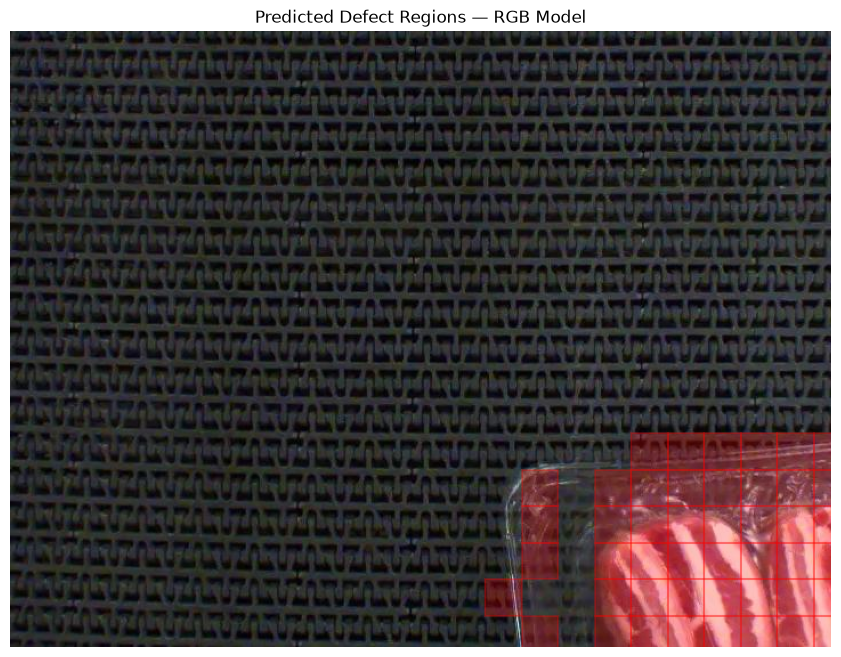

In [189]:
# Display the original validation image.
fig, ax = plt.subplots(figsize=(12, 8))
ax.imshow(example_image)

# Overlay predicted defective patches in red.
for patch, prediction in zip(example_patches, example_predictions):

    # Only draw patches classified as DEFECT.
    if prediction == 1:

        rectangle = patches.Rectangle(
            (patch["x"], patch["y"]),
            patch["width"],
            patch["height"],
            linewidth=1.5,
            edgecolor="red",
            facecolor="red",
            alpha=0.25
        )

        ax.add_patch(rectangle)

ax.set_title(
    "Predicted Defect Regions — RGB Model"
)

ax.axis("off")
plt.show()

## 8. Compare Predicted Regions with COCO Ground Truth

This section compares predicted defect patches against the
original COCO bounding-box annotations.

Red regions represent patches predicted as defective by the
trained logistic regression classifier.

Blue bounding boxes represent ground-truth defects from COCO.

The annotations are used exclusively for evaluation and are
not supplied to the model during prediction.

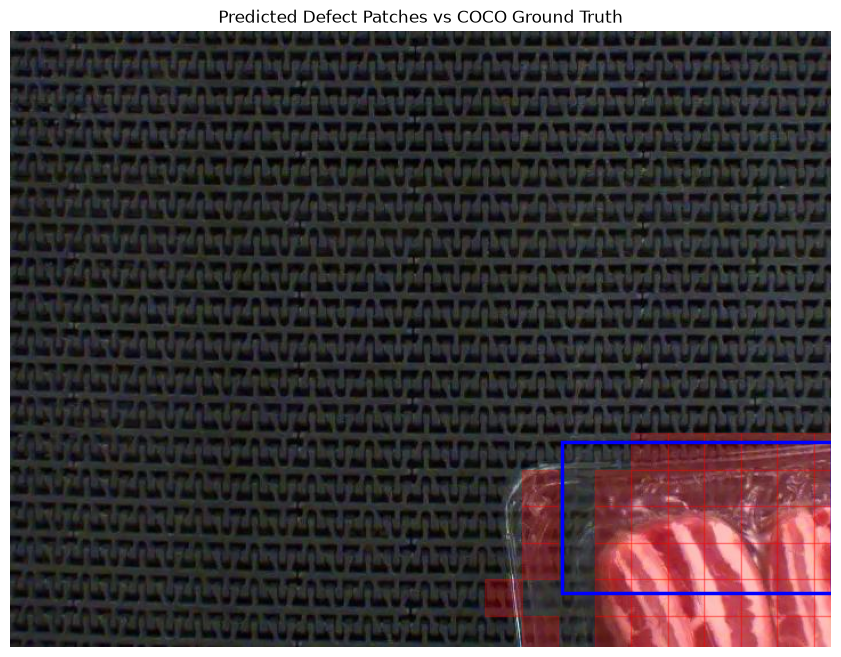

In [190]:
# Retrieve COCO annotations belonging to the example image.
example_annotations = [
    annotation
    for annotation in valid_annotations
    if annotation["image_id"] == example_image_info["id"]
]

# Create the visualisation.
fig, ax = plt.subplots(figsize=(12, 8))

# Display the original RGB image.
ax.imshow(example_image)

# Overlay patches predicted as DEFECT in red.
for patch, prediction in zip(example_patches, example_predictions):

    if prediction == 1:
        rectangle = patches.Rectangle(
            (patch["x"], patch["y"]),
            patch["width"],
            patch["height"],
            linewidth=1,
            edgecolor="red",
            facecolor="red",
            alpha=0.25
        )

        ax.add_patch(rectangle)

# Overlay the actual COCO defect bounding boxes in blue.
for annotation in example_annotations:

    x, y, width, height = annotation["bbox"]

    rectangle = patches.Rectangle(
        (x, y),
        width,
        height,
        linewidth=2.5,
        edgecolor="blue",
        facecolor="none"
    )

    ax.add_patch(rectangle)

ax.set_title("Predicted Defect Patches vs COCO Ground Truth")
ax.axis("off")

plt.show()

## 9. Predict Defect Regions Across the Validation Dataset

This section applies the trained defect-region classifier to all
images in the independent validation dataset.

Each validation image is divided into 32 × 32-pixel patches,
and the six RGB statistical features are extracted.

The trained logistic regression pipeline predicts whether each
patch contains a defect.

COCO annotations are not used to generate predictions.
They are reserved for subsequent evaluation.

In [191]:
# Initialise a list to store predictions for every validation patch.
prediction_records = []

# Process each image in the existing validation dataset.
for image_info in valid_images:

    # Retrieve the image identifier and filename.
    image_id = image_info["id"]
    filename = image_info["file_name"]

    # Construct the path to the validation image.
    image_path = VALID_DIR / filename

    # Load the image in RGB format.
    with Image.open(image_path) as img:
        current_image = img.convert("RGB")

    # Divide the image into patches using the same method
    # and patch size as Notebook 06.
    image_patches = extract_patches(
        current_image,
        patch_size=PATCH_SIZE
    )

    # Extract the six RGB features from every patch.
    image_features = pd.DataFrame([
        extract_rgb_features(patch["rgb"])
        for patch in image_patches
    ])

    # Ensure features are supplied in their original training order.
    image_features = image_features[RGB_FEATURE_COLUMNS]

    # Generate predictions using the trained classifier.
    # No COCO defect annotations are accessed here.
    predictions = region_model.predict(image_features)

    # Store each prediction alongside its source image
    # and patch coordinates for later evaluation.
    for patch, prediction in zip(image_patches, predictions):

        prediction_records.append({
            "image_id": image_id,
            "filename": filename,
            "x": patch["x"],
            "y": patch["y"],
            "width": patch["width"],
            "height": patch["height"],
            "prediction": int(prediction)
        })

# Convert predictions into a DataFrame.
predictions_df = pd.DataFrame(prediction_records)

# Display a summary of the completed predictions.
print("Validation prediction complete.")
print("Images processed:", predictions_df["image_id"].nunique())
print("Total patches predicted:", len(predictions_df))

print("\nPredicted class distribution:")
print(predictions_df["prediction"].value_counts().sort_index())

display(predictions_df.head())

Validation prediction complete.
Images processed: 120
Total patches predicted: 46920

Predicted class distribution:
prediction
0    40600
1     6320
Name: count, dtype: int64


,image_id,filename,x,y,width,height,prediction
0,0,frame_with_red_8649_jpg.rf.a4d923187143603a280...,0,0,32,32,0
1,0,frame_with_red_8649_jpg.rf.a4d923187143603a280...,32,0,32,32,0
2,0,frame_with_red_8649_jpg.rf.a4d923187143603a280...,64,0,32,32,0
3,0,frame_with_red_8649_jpg.rf.a4d923187143603a280...,96,0,32,32,0
4,0,frame_with_red_8649_jpg.rf.a4d923187143603a280...,128,0,32,32,0


## 10. Generate Validation Ground-Truth Labels

This section uses COCO bounding-box annotations to establish
the ground-truth classification of each validation patch.

The same 20% overlap threshold used during training is applied.

Patches are classified as:
- 0: NORMAL
- 1: DEFECT
- -1: AMBIGUOUS

Ambiguous patches are excluded from performance evaluation
to maintain consistency with the training dataset.

Ground-truth annotations are used only after model predictions
have been generated, preventing target leakage.

In [192]:
def calculate_patch_overlap(patch, bbox):
    """
    Calculate the fraction of a patch covered by a COCO bounding box.

    Parameters
    ----------
    patch : dict
        Patch coordinates and dimensions.

    bbox : list
        COCO bounding box [x, y, width, height].

    Returns
    -------
    float
        Bounding-box intersection area divided by patch area.
    """

    # Calculate patch boundaries.
    px1 = patch["x"]
    py1 = patch["y"]
    px2 = px1 + patch["width"]
    py2 = py1 + patch["height"]

    # Calculate bounding-box boundaries.
    bx1, by1, bw, bh = bbox

    bx2 = bx1 + bw
    by2 = by1 + bh

    # Calculate overlapping rectangle dimensions.
    intersection_width = max(
        0, min(px2, bx2) - max(px1, bx1)
    )

    intersection_height = max(
        0, min(py2, by2) - max(py1, by1)
    )

    # Calculate the fraction of patch area covered.
    intersection_area = intersection_width * intersection_height
    patch_area = patch["width"] * patch["height"]

    return intersection_area / patch_area


def label_patch(patch, image_annotations, defect_threshold=0.20):
    """
    Assign a ground-truth label based on annotation overlap.

    Returns
    -------
    int
        1 = DEFECT, 0 = NORMAL, -1 = AMBIGUOUS.
    """

    # Find the greatest overlap with any annotation.
    max_overlap = max(
        (
            calculate_patch_overlap(patch, annotation["bbox"])
            for annotation in image_annotations
        ),
        default=0.0
    )

    # Apply the same labelling rules as Notebook 06.
    if max_overlap >= defect_threshold:
        return 1

    elif max_overlap == 0:
        return 0

    else:
        return -1

In [193]:
# Create a lookup table associating image IDs with annotations.
annotations_by_image = defaultdict(list)

for annotation in valid_annotations:
    annotations_by_image[annotation["image_id"]].append(annotation)

# Store the ground-truth labels for every predicted patch.
ground_truth_labels = []

# Iterate over the existing prediction records.
for record in prediction_records:

    # Identify the annotations belonging to this patch's image.
    image_annotations = annotations_by_image[record["image_id"]]

    # Calculate the ground-truth label using COCO annotations.
    ground_truth = label_patch(
        record,
        image_annotations,
        defect_threshold=DEFECT_THRESHOLD
    )

    ground_truth_labels.append(ground_truth)

# Add evaluation labels to the predictions DataFrame.
predictions_df["ground_truth"] = ground_truth_labels

print("Ground-truth labelling complete.")

print("\nGround-truth distribution:")
print(predictions_df["ground_truth"].value_counts().sort_index())

Ground-truth labelling complete.

Ground-truth distribution:
ground_truth
-1      294
 0    42050
 1     4576
Name: count, dtype: int64


## 11. Evaluate Defect Region Classification

This section evaluates patch-level classification performance
against COCO-derived validation ground truth.

Ambiguous patches are excluded from evaluation.

The following metrics are calculated:
- Overall accuracy
- Balanced accuracy
- Precision and recall
- F1 score
- Confusion matrix

Particular emphasis is placed on DEFECT recall and precision
because missed defects and false alarms have different
consequences in industrial inspection.

In [194]:
# Exclude ambiguous patches from the evaluation dataset.
evaluation_df = predictions_df[
    predictions_df["ground_truth"] != -1
].copy()

# Extract the actual and predicted patch labels.
y_true = evaluation_df["ground_truth"]
y_pred = evaluation_df["prediction"]

print("Patches evaluated:", len(evaluation_df))

print(
    "Ambiguous patches excluded:",
    len(predictions_df) - len(evaluation_df)
)

Patches evaluated: 46626
Ambiguous patches excluded: 294


In [195]:
# Calculate overall accuracy.
accuracy = accuracy_score(y_true, y_pred)

# Calculate balanced accuracy to account for class imbalance.
balanced_accuracy = balanced_accuracy_score(
    y_true,
    y_pred
)

# Display the main classification metrics.
print(f"Overall accuracy: {accuracy:.2%}")
print(f"Balanced accuracy: {balanced_accuracy:.2%}")

# Display precision, recall and F1 score for both classes.
print("\nClassification report:")

print(
    classification_report(
        y_true,
        y_pred,
        labels=[0, 1],
        target_names=["NORMAL", "DEFECT"],
        digits=3,
        zero_division=0
    )
)

Overall accuracy: 93.59%
Balanced accuracy: 89.75%

Classification report:
              precision    recall  f1-score   support

      NORMAL      0.983     0.945     0.964     42050
      DEFECT      0.628     0.850     0.722      4576

    accuracy                          0.936     46626
   macro avg      0.806     0.897     0.843     46626
weighted avg      0.948     0.936     0.940     46626



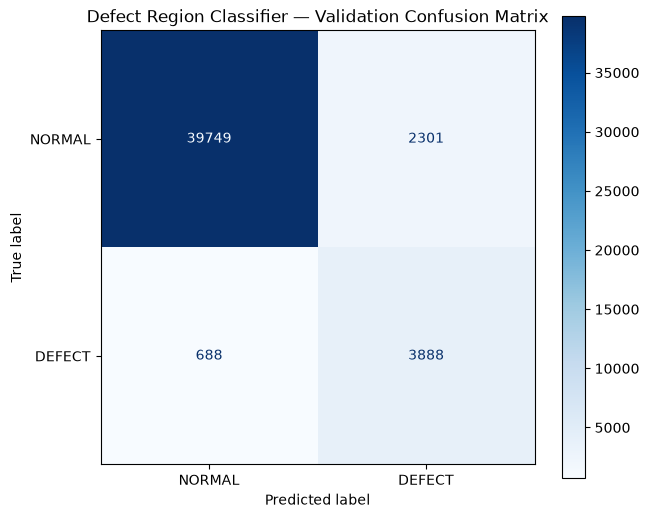

In [196]:
# Calculate the confusion matrix using a fixed class order.
cm = confusion_matrix(
    y_true,
    y_pred,
    labels=[0, 1]
)

# Create a labelled confusion-matrix visualisation.
display_matrix = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["NORMAL", "DEFECT"]
)

fig, ax = plt.subplots(figsize=(7, 6))

display_matrix.plot(
    ax=ax,
    cmap="Blues",
    values_format="d"
)

ax.set_title("Defect Region Classifier — Validation Confusion Matrix")

plt.show()

## 11. Generate Image-Level PASS/FAIL Predictions

This section combines individual patch predictions into a
single PASS or FAIL classification for each validation image.

An image is classified as FAIL if one or more patches are
predicted as defective.

An image is classified as PASS if all patches are predicted
as normal.

This initial rule will be evaluated against COCO-derived
image-level ground truth.

In [209]:
# Define the maximum number of defective regions allowed
# before the entire image is classified as FAIL.
MAX_DEFECTS = 37

# Group patch predictions by their original source image.
# Count the number of patches classified as defective (1).
image_predictions_df = (
    predictions_df
    .groupby(["image_id", "filename"], as_index=False)
    .agg(
        predicted_defect_count=("prediction", "sum")
    )
)

# Apply the new image-level classification threshold.
# 0 = PASS: 36 or fewer defective regions.
# 1 = FAIL: More than 36 defective regions.
image_predictions_df["predicted_label"] = (
    image_predictions_df["predicted_defect_count"] > MAX_DEFECTS
).astype(int)

# Convert numerical predictions to descriptive labels.
image_predictions_df["predicted_class"] = (
    image_predictions_df["predicted_label"]
    .map({0: "PASS", 1: "FAIL"})
)

# Display the first five image-level predictions.
display(image_predictions_df.head())

,image_id,filename,predicted_defect_count,predicted_label,predicted_class
0,0,frame_with_red_8649_jpg.rf.a4d923187143603a280...,46,1,FAIL
1,1,frame_with_red_2115_jpg.rf.2eb3c4cff72bd0c8282...,36,0,PASS
2,2,frame_with_red_8627_jpg.rf.e0f16b203d1ac259b6c...,52,1,FAIL
3,3,frame_with_red_2289_jpg.rf.e4cabf0fac8d843cef9...,68,1,FAIL
4,4,frame_with_red_8526_jpg.rf.8a95c208e25b872ba67...,66,1,FAIL


In [210]:
# Count the total number of images assigned to each class.
predicted_counts = (
    image_predictions_df["predicted_class"]
    .value_counts()
    .reindex(["PASS", "FAIL"], fill_value=0)
)

print("Predicted image classifications:")
print(predicted_counts.to_string())

print("\nTotal validation images:", len(image_predictions_df))

Predicted image classifications:
predicted_class
PASS     16
FAIL    104

Total validation images: 120


In [211]:
# Identify image IDs containing at least one COCO defect annotation.
# This information is used for evaluation only.
annotated_image_ids = {
    annotation["image_id"]
    for annotation in valid_annotations
}

# Assign ground-truth labels to the completed image predictions.
# An annotation indicates FAIL; otherwise the image is PASS.
image_predictions_df["actual_label"] = (
    image_predictions_df["image_id"]
    .isin(annotated_image_ids)
    .astype(int)
)

# Convert the numerical ground-truth labels into class names.
image_predictions_df["actual_class"] = (
    image_predictions_df["actual_label"]
    .map({0: "PASS", 1: "FAIL"})
)

# Compare predicted and actual classifications.
display(
    image_predictions_df[
        [
            "filename",
            "predicted_defect_count",
            "predicted_class",
            "actual_class"
        ]
    ].head()
)

,filename,predicted_defect_count,predicted_class,actual_class
0,frame_with_red_8649_jpg.rf.a4d923187143603a280...,46,FAIL,FAIL
1,frame_with_red_2115_jpg.rf.2eb3c4cff72bd0c8282...,36,PASS,PASS
2,frame_with_red_8627_jpg.rf.e0f16b203d1ac259b6c...,52,FAIL,FAIL
3,frame_with_red_2289_jpg.rf.e4cabf0fac8d843cef9...,68,FAIL,FAIL
4,frame_with_red_8526_jpg.rf.8a95c208e25b872ba67...,66,FAIL,FAIL


In [212]:
# Extract the ground-truth and predicted image classifications.
y_true = image_predictions_df["actual_label"]
y_pred = image_predictions_df["predicted_label"]

# Calculate performance metrics at the image level.
accuracy = accuracy_score(y_true, y_pred)

balanced_accuracy = balanced_accuracy_score(y_true, y_pred)

# Display overall classification performance.
print(f"Image-level accuracy: {accuracy:.2%}")
print(f"Image-level balanced accuracy: {balanced_accuracy:.2%}")

# Display class-specific precision, recall and F1 scores.
print("\nImage-level classification report:")

print(
    classification_report(
        y_true,
        y_pred,
        labels=[0, 1],
        target_names=["PASS", "FAIL"],
        digits=3,
        zero_division=0
    )
)

Image-level accuracy: 85.00%
Image-level balanced accuracy: 66.71%

Image-level classification report:
              precision    recall  f1-score   support

        PASS      0.375     0.429     0.400        14
        FAIL      0.923     0.906     0.914       106

    accuracy                          0.850       120
   macro avg      0.649     0.667     0.657       120
weighted avg      0.859     0.850     0.854       120



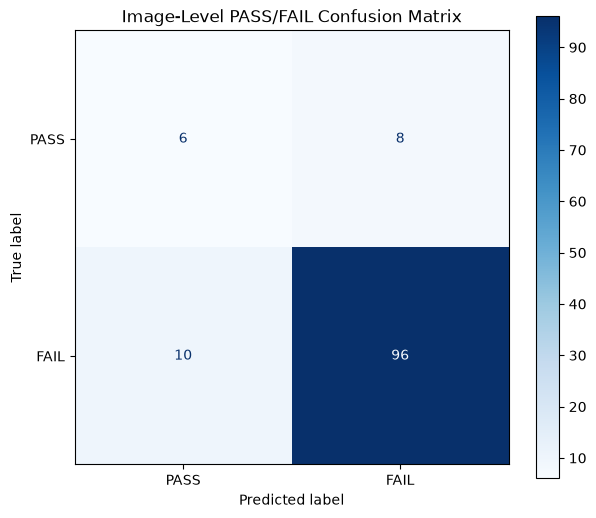

In [213]:
# Generate confusion matrix for complete image classifications.
cm = confusion_matrix(
    y_true,
    y_pred,
    labels=[0, 1]
)

# Display the confusion matrix.
display_matrix = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["PASS", "FAIL"]
)

fig, ax = plt.subplots(figsize=(7, 6))

display_matrix.plot(
    ax=ax,
    cmap="Blues",
    values_format="d"
)

ax.set_title("Image-Level PASS/FAIL Confusion Matrix")

plt.show()

## 14. Analyse Predicted Defect Counts

This section investigates whether the number of patches predicted
as defective differs between PASS and FAIL validation images.

The objective is to determine whether image-level classification
could be improved by considering the extent of predicted defective
regions rather than the presence of any single positive patch.

COCO ground-truth labels are used only for retrospective evaluation.

In [214]:
# Group images by their actual PASS/FAIL classification.
# Calculate descriptive statistics for the number of
# patches predicted as defective.

defect_count_summary = (
    image_predictions_df
    .groupby("actual_class")["predicted_defect_count"]
    .describe()
)

# Display the distributions for both classes.
display(defect_count_summary)

,count,mean,std,min,25%,50%,75%,max
actual_class,,,,,,,,
FAIL,106.0,54.075472,23.025327,27.0,44.00,49.0,56.75,196.0
PASS,14.0,42.000000,9.248701,28.0,35.25,41.0,50.00,57.0
